In [1]:
#imports 
from xgboost import XGBClassifier
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import (train_test_split, RandomizedSearchCV)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, confusion_matrix)


In [2]:
df_undersampled_clean = pd.read_csv("/home/desktop/Optimizing-P2P-Loan-Thresholds-for-Borrowers-Using-LendingClub-Data-/dataset/clean_undersampled.csv", low_memory=False)

In [3]:
#MACHINE LEARNIGN TIME!!
y = df_undersampled_clean['profitable']
X = df_undersampled_clean.drop(columns=['profitable'])

In [4]:
# spliting the test set and the training set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=42, stratify=y)

In [5]:
# splitting the training portion into train and validation
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.1765, random_state = 42, stratify=y_train)

In [6]:
#No we have  an 80/15/15 split with our data
print(len(X_train), len(X_val), len(X_test))
print(y_train.mean(), y_val.mean(), y_test.mean())  # all should be ~0.5

384407 82390 82377
0.5000013007047218 0.5 0.499993930344635


In [7]:
#Fit
XGBoost_model = XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1, eval_metric='logloss')
XGBoost_model.fit(X, y)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [8]:
#Now using our validation set to see more performance on seen data
y_pred = XGBoost_model.predict(X_val)

#test validation set accuracy
print("Accuracy:", accuracy_score(y_val, y_pred))
print("Precision:", precision_score(y_val, y_pred))
print("Recall:   ", recall_score(y_val, y_pred))
print("F1:       ", f1_score(y_val, y_pred))
print("ROC AUC:  ", roc_auc_score(y_val, XGBoost_model.predict_proba(X_val)[:, 1]))
print()
print(classification_report(y_val, y_pred))
print(confusion_matrix(y_val, y_pred))

Accuracy: 0.6830440587449933
Precision: 0.6869839065638406
Recall:    0.6725087996116034
F1:        0.6796692917249332
ROC AUC:   0.7499538889465305

              precision    recall  f1-score   support

           0       0.68      0.69      0.69     41195
           1       0.69      0.67      0.68     41195

    accuracy                           0.68     82390
   macro avg       0.68      0.68      0.68     82390
weighted avg       0.68      0.68      0.68     82390

[[28572 12623]
 [13491 27704]]


In [9]:
#Now let see the feature importance
fi = pd.Series(XGBoost_model.feature_importances_, index = X.columns)
fi.sort_values(ascending = False)

grade            0.321798
sub_grade        0.187741
term_months      0.041087
issue_year       0.031788
max_bal_bc       0.022788
                   ...   
addr_state_TN    0.000000
addr_state_RI    0.000000
addr_state_TX    0.000000
addr_state_WY    0.000000
addr_state_WI    0.000000
Length: 151, dtype: float32

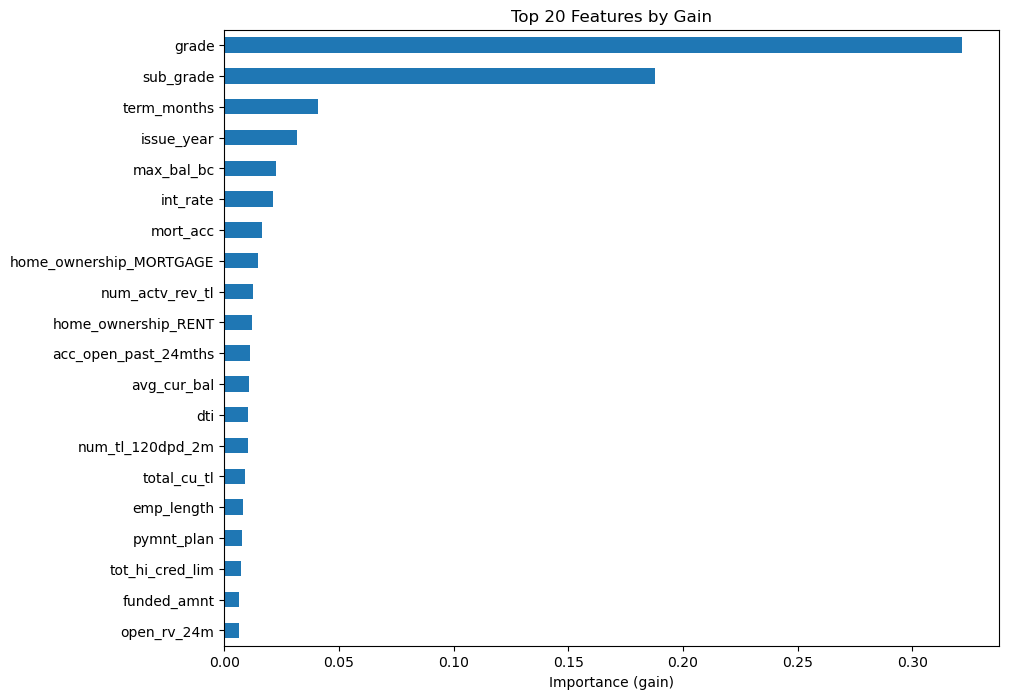

In [10]:
fi = pd.Series(XGBoost_model.feature_importances_, index=X.columns)
fi.sort_values(ascending=False).head(20).plot(kind='barh', figsize=(10, 8))
plt.title('Top 20 Features by Gain')
plt.xlabel('Importance (gain)')
plt.gca().invert_yaxis()
plt.show()

In [11]:
#No lets train with some hyper parameter ttuning!!

param_grid = {
    'n_estimators': [2000], #number of trees 
    'learning_rate': [0.01, 0.1, 0.2, 0.05], #The step size for each new tree
    'max_depth': [3, 6, 9], #how deep each individual tree can grow. A depth-4 tree can make up to 4 sequential splits
    'early_stopping_rounds': [50], # stop training if validation performance doesn't improve for 50 consecutive rounds
    'min_child_weight': [1, 3, 5, 10], # minumum sum of instance weights
    'subsample': [0.6, 0.7, 0.8, 1.0], #What fraction fo rows each tree sees
    'reg_alpha': [0, 0.01, 0.1, 1, 10, 100], # Sets the strength of the L1 regularization. Adds the value of each coeffiecint as a penalty tterm to the loss function. AUto matic feature selection.
    'reg_lambda': [0.5, 0.7, 1, 1.3] # Sets the strength of the L2 regularization. Adds the sum of squares of the coeffiecient as a penalty to the loss fucntoin. imporantant when all features are imporatnnt or correlated and shoudl afect the model equally. 
}


In [12]:
xgb_model = XGBClassifier(random_state = 42, early_stopping_rounds = 50, eval_metric = 'logloss')

#use cross validation to determine wich sets are best.
grid_search = RandomizedSearchCV(xgb_model, param_grid, cv=10, scoring="roc_auc", n_iter = 100, n_jobs = -1, verbose = 2, random_state = 42)
grid_search.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=200)

best_xgb = grid_search.best_estimator_

#Best Params from tuning
print("Best Pramters: ", grid_search.best_params_)
print("Best Accuracy: ", grid_search.best_score_)

Fitting 10 folds for each of 100 candidates, totalling 1000 fits
[0]	validation_0-logloss:0.68206
[0]	validation_0-logloss:0.68209
[0]	validation_0-logloss:0.68565
[0]	validation_0-logloss:0.68202
[0]	validation_0-logloss:0.68210
[0]	validation_0-logloss:0.68205
[0]	validation_0-logloss:0.68204
[0]	validation_0-logloss:0.68565
[0]	validation_0-logloss:0.68205
[0]	validation_0-logloss:0.68210
[0]	validation_0-logloss:0.68564
[0]	validation_0-logloss:0.68561
[0]	validation_0-logloss:0.68563
[0]	validation_0-logloss:0.68559
[0]	validation_0-logloss:0.68206
[0]	validation_0-logloss:0.68178
[200]	validation_0-logloss:0.59800
[200]	validation_0-logloss:0.59783
[200]	validation_0-logloss:0.59766
[200]	validation_0-logloss:0.59766
[200]	validation_0-logloss:0.59793
[200]	validation_0-logloss:0.59792
[200]	validation_0-logloss:0.59777
[200]	validation_0-logloss:0.59802
[200]	validation_0-logloss:0.59776
[200]	validation_0-logloss:0.59768
[200]	validation_0-logloss:0.59403
[200]	validation_0-log

In [15]:
#Now using the best model on our validation set
y_pred = best_xgb.predict(X_test)

test_accuracy = accuracy_score(y_test, y_pred)

#test set accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:   ", recall_score(y_test, y_pred))
print("F1:       ", f1_score(y_test, y_pred))
print("ROC AUC:  ", roc_auc_score(y_test, best_xgb.predict_proba(X_test)[:, 1]))
print()
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.6803962271022251
Precision: 0.6847064087903346
Recall:    0.668714188598621
F1:        0.6766158154617142
ROC AUC:   0.7465263675560936

              precision    recall  f1-score   support

           0       0.68      0.69      0.68     41189
           1       0.68      0.67      0.68     41188

    accuracy                           0.68     82377
   macro avg       0.68      0.68      0.68     82377
weighted avg       0.68      0.68      0.68     82377

[[28506 12683]
 [13645 27543]]


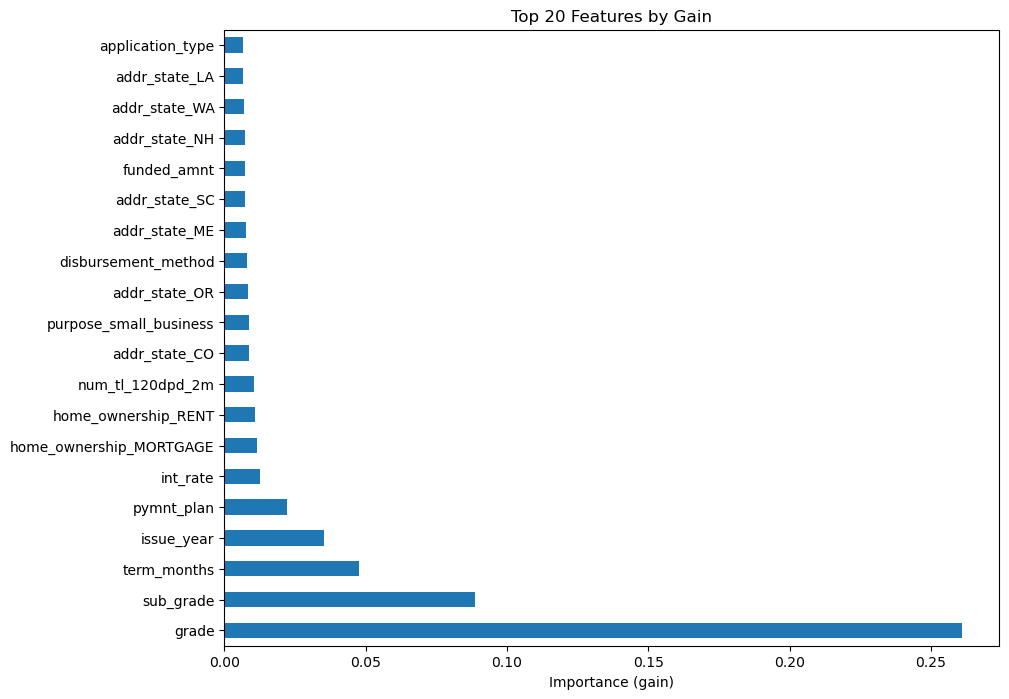

In [16]:
fi = pd.Series(best_xgb.feature_importances_, index=X.columns)
fi.sort_values(ascending=False).head(20).plot(kind='barh', figsize=(10, 8))
plt.title('Top 20 Features by Gain')
plt.xlabel('Importance (gain)')
plt.gca()#.invert_yaxis()
plt.show()